# EDA — Network Slicing Dataset + Pipeline Walkthrough

Dataset: Farreras et al. 2024 (Zenodo 10610616), untarred result dir
`results_slicing_WFQ_1000_routing_7800_7899` (100 samples).

This notebook does three things:
1. **EDA** — what the load and KPI distributions look like.
2. **Model** — how we turn per-slice load into replicas/delay/loss (capacity model) and how slices map to budgets.
3. **Manual test** — one sample walked through the full pipeline (Tier-1 signals -> payload -> decision -> gate -> outcome -> oracle).


In [1]:
%matplotlib inline
import sys, os
for _p in (os.getcwd(), os.path.dirname(os.getcwd())):
    if os.path.exists(os.path.join(_p, "src")):
        sys.path.insert(0, _p)
        os.chdir(_p)
        break

import json
import numpy as np
import matplotlib.pyplot as plt

from src import capacity_model as cm
from src import benchmark as bench
from src.dataset import load_result_dir, sorted_by_load, loads_by_slice
from src.kpi_predictor import MLPRegressor, violation_prob
from src.forecaster import LinearForecaster
from src.llm_compiler import build_payload, call_stub
from src import gate
from src.oracle import oracle_slices

DATA = "datasets/generation_netwok_slicing_dataset/2.2.1-10kprocessed/results_slicing_WFQ_1000_routing_7800_7899"


In [2]:
states, delays, losses = load_result_dir(DATA)
states, delays, losses = sorted_by_load(states, delays, losses)
delays = np.asarray(delays); losses = np.asarray(losses)
agg = np.asarray([sum(s.values()) for s in states])
lbs = loads_by_slice(states)

print(f"samples = {len(states)}")
print(f"aggregate load (Mbps): min={agg.min():.0f}  max={agg.max():.0f}  mean={agg.mean():.0f}")
print("one state (per-slice load, Mbps):", {s: round(states[0][s]) for s in cm.SLICES})


samples = 100
aggregate load (Mbps): min=47  max=810  mean=376
one state (per-slice load, Mbps): {'eMBB': 36, 'URLLC': 7, 'mMTC': 4}


In [3]:
import pandas as pd

df = pd.DataFrame({
    "eMBB_load_mbps": [s["eMBB"] for s in states],
    "URLLC_load_mbps": [s["URLLC"] for s in states],
    "mMTC_load_mbps": [s["mMTC"] for s in states],
    "delay": delays,
    "loss": losses,
})
df.head(10)


,eMBB_load_mbps,URLLC_load_mbps,mMTC_load_mbps,delay,loss
0,36.0,7.0,4.4,0.021893,0.566685
1,36.0,31.5,5.2,0.035903,0.572249
2,36.0,24.5,14.2,0.022491,0.633502
3,54.0,21.0,1.8,0.019526,0.361047
4,36.0,45.5,1.8,0.002419,0.004915
5,72.0,21.0,1.6,0.009122,0.057373
6,36.0,59.5,3.0,0.006412,0.047454
7,36.0,49.0,13.6,0.003780,0.081456
8,72.0,24.5,25.6,0.010105,0.338414
9,72.0,49.0,5.8,0.003349,0.058303


## 1. Load distribution

Each sample is a per-slice offered load dict `{eMBB, URLLC, mMTC}` (Mbps).
`maxAvgLambda` is constant, so the per-slice bandwidth is the load signal.

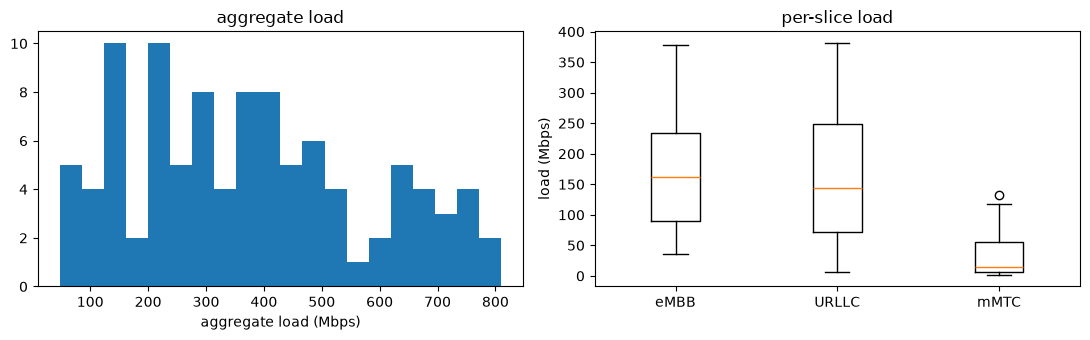

eMBB: min=36  max=378  mean=174
URLLC: min=7  max=382  mean=170
mMTC: min=2  max=132  mean=32


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(agg, bins=20)
ax[0].set_xlabel("aggregate load (Mbps)"); ax[0].set_title("aggregate load")
ax[1].boxplot([lbs[s] for s in cm.SLICES], tick_labels=cm.SLICES)
ax[1].set_ylabel("load (Mbps)"); ax[1].set_title("per-slice load")
plt.tight_layout(); plt.show()

for s in cm.SLICES:
    print(f"{s}: min={min(lbs[s]):.0f}  max={max(lbs[s]):.0f}  mean={np.mean(lbs[s]):.0f}")


## 2. KPI (delay / loss)

The dataset also records global delay and loss rate per sample. We use these
only to calibrate `base_delay` and train the MLP; the control loop re-derives
KPI from the capacity model.

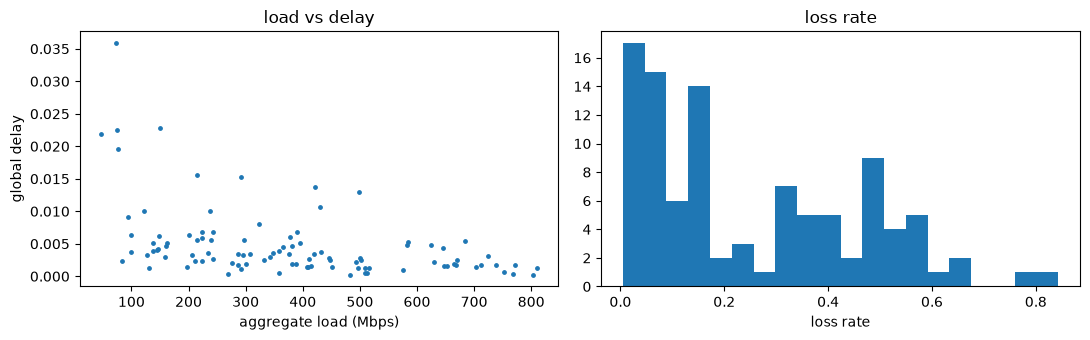

delay: min=0.00021  max=0.03590
loss : min=0.005  max=0.843


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(agg, delays, s=6)
ax[0].set_xlabel("aggregate load (Mbps)"); ax[0].set_ylabel("global delay")
ax[0].set_title("load vs delay")
ax[1].hist(losses, bins=20)
ax[1].set_xlabel("loss rate"); ax[1].set_title("loss rate")
plt.tight_layout(); plt.show()

print(f"delay: min={delays.min():.5f}  max={delays.max():.5f}")
print(f"loss : min={losses.min():.3f}  max={losses.max():.3f}")


## 3. Slice composition and budgets

How we *use* the slices: each slice type gets its own `NFConfig` — a
per-replica capacity and KPI budget. URLLC = tight delay, eMBB = loose delay +
high throughput, mMTC = strict loss.

In [6]:
mean_load = {s: np.mean(lbs[s]) for s in cm.SLICES}
total = sum(mean_load.values())
for s in cm.SLICES:
    print(f"{s}: mean load {mean_load[s]:.0f} Mbps ({100*mean_load[s]/total:.0f}% of total)")

base = delays.min()
caps = {s: max(np.percentile(lbs[s], 95) / (5 * 0.7), 1.0) for s in cm.SLICES}
cfgs = cm.build_slice_configs(caps, base)
for s in cm.SLICES:
    c = cfgs[s]
    print(f"{s}: cap/replica={c.cap_per_replica_mbps:.0f} Mbps, "
          f"delay_budget={c.delay_budget/c.base_delay:.0f}x base, loss_budget={c.loss_budget}")


eMBB: mean load 174 Mbps (46% of total)
URLLC: mean load 170 Mbps (45% of total)
mMTC: mean load 32 Mbps (9% of total)
eMBB: cap/replica=98 Mbps, delay_budget=30x base, loss_budget=0.02
URLLC: cap/replica=101 Mbps, delay_budget=4x base, loss_budget=0.005
mMTC: cap/replica=29 Mbps, delay_budget=15x base, loss_budget=0.005


## 4. Capacity model (how we model)

```
effective_capacity = replicas * cap_per_replica
rho = load / capacity
delay = base_delay / (1 - rho)  if rho < 1, else max_delay
loss  = (load - capacity) / load if overloaded, else 0
violation = delay > delay_budget OR loss > loss_budget
```
`required_replicas = ceil(load / (cap_per_replica * target_util))` keeps
utilization at the 0.7 target.

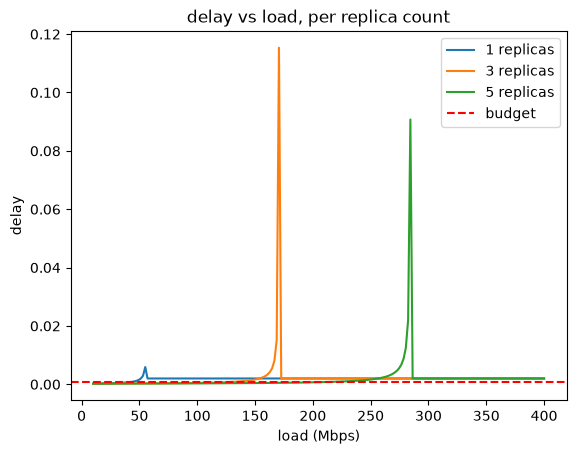

In [7]:
nf = cm.NFConfig(cap_per_replica_mbps=57, base_delay=0.0002, delay_budget=0.0008, max_delay=0.002)
loads = np.linspace(10, 400, 200)
for r in [1, 3, 5]:
    d = [cm.delay(L, r, nf) for L in loads]
    plt.plot(loads, d, label=f"{r} replicas")
plt.axhline(nf.delay_budget, color="r", ls="--", label="budget")
plt.xlabel("load (Mbps)"); plt.ylabel("delay"); plt.legend()
plt.title("delay vs load, per replica count")
plt.show()


## 5. Manual pipeline test (one sample)

Walk sample `i=40` through the full loop: observe -> Tier-1 signals ->
payload -> stub decision -> gate -> resulting KPI -> oracle.

In [8]:
cfgs = bench.build_cfgs(states, delays)
agg_nf = bench.build_agg_nf(states, delays)
pred = MLPRegressor().fit(agg, delays)
fc = LinearForecaster(window=5)

i = 40
state = states[i]
print(f"step t={i}, per-slice load (Mbps):", {s: round(state[s]) for s in cm.SLICES})

# 1. observation at min replicas (current KPI from the capacity model)
obs = {"t": i, "slices": {s: {
    "load": state[s], "replicas": cfgs[s].min_replicas,
    "delay": cm.delay(state[s], cfgs[s].min_replicas, cfgs[s]),
    "loss": cm.loss(state[s], cfgs[s].min_replicas, cfgs[s]),
} for s in cm.SLICES}}
print("obs (min replicas):",
      {s: (round(obs["slices"][s]["delay"], 5), round(obs["slices"][s]["loss"], 3)) for s in cm.SLICES})

# 2. Tier-1 signals: forecast + MLP -> p_violation
history = list(agg[:i + 1])
forecast = fc.predict(history)
pv = violation_prob(float(pred.predict([forecast])[0]), agg_nf.delay_budget)
print(f"forecast={forecast:.0f} Mbps, p_violation={pv:.2f}")

# 3. payload to the LLM
payload = build_payload(obs, forecast, pv, cfgs)
print(json.dumps(payload, indent=2)[:500], "...")

# 4. decision (stub = deterministic rule)
action = call_stub(payload, cfgs)["actions"]
print("stub action:", action)

# 5. verification gate
ok, reason = gate.check_slices(action, cfgs)
print("gate:", ok, reason)

# 6. resulting KPI at the chosen replicas
for s in cm.SLICES:
    d = cm.delay(state[s], action[s], cfgs[s])
    l = cm.loss(state[s], action[s], cfgs[s])
    v = cm.violation(d, l, cfgs[s])
    print(f"{s}: action={action[s]} -> delay={d:.5f} loss={l:.3f} violation={v}")

# 7. hindsight oracle: what was actually needed (future P95)
o = oracle_slices(lbs, i, action, cfgs)
for s in cm.SLICES:
    req, label, delta = o[s]
    print(f"{s}: oracle required={req} label={label} delta={delta}")


step t=40, per-slice load (Mbps): {'eMBB': 126, 'URLLC': 164, 'mMTC': 5}
obs (min replicas): {'eMBB': (0.01065, 0.224), 'URLLC': (0.00213, 0.386), 'mMTC': (0.00026, 0.0)}
forecast=297 Mbps, p_violation=0.79
{
  "slices": {
    "eMBB": {
      "kpi_target": {
        "delay": 0.00639,
        "loss": 0.02
      },
      "kpi_now": {
        "delay": 0.01065,
        "loss": 0.2244897959183674
      },
      "load_mbps": 126.0,
      "replicas": 1,
      "max_replicas": 5
    },
    "URLLC": {
      "kpi_target": {
        "delay": 0.000852,
        "loss": 0.005
      },
      "kpi_now": {
        "delay": 0.00213,
        "loss": 0.38571428571428573
      },
      "load_mbps": 164.5,
      "replica ...
stub action: {'eMBB': 2, 'URLLC': 3, 'mMTC': 1}
gate: True ok
eMBB: action=2 -> delay=0.00060 loss=0.000 violation=False
URLLC: action=3 -> delay=0.00047 loss=0.000 violation=False
mMTC: action=1 -> delay=0.00026 loss=0.000 violation=False
eMBB: oracle required=4 label=up delta=2
URLLC: 